# Generalized Evolution Strategies for Mixed-Variable Optimization

## Experiment 1: Equal-Budget Benchmark Comparison

> Prototype 1 vs Baseline Optimizers (Isotropic ES and CMA-ES)

> This notebook compares Prototype 1 (our custom generalized ES model) against the following baseline implementations:
1. **Isotropic ES (Simple Self-Adaptive)**: Uses a single global $\sigma$ ($n_\sigma = 1$, $n_\alpha = 0$).
2. **sep-CMA-ES (Separable CMA-ES)**: Diagonal CMA-ES from the `pycma` library (`CMA_diagonal=True`).
3. **Standard CMA-ES (Upper Bound)**: Full-covariance CMA-ES used strictly as a performance ceiling.

All comparisons use the **real-valued block only** for fairness, evaluated on
standard benchmark functions with equal evaluation budgets and 10 seeds.

In [2]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = None
for parent in [cwd] + list(cwd.parents):
    if (parent / "src").is_dir():
        project_root = parent
        break
if project_root is None:
    project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.benchmarks.functions import BENCHMARKS
from experiments.experiment_1.runners.run_experiment_1 import (
    RUNNERS,
    run_all_experiments,
    save_experiment_1_traces,
    load_experiment_1_traces,
    compute_wilcoxon_table_exp1,
)
from experiments.experiment_1.runners.plotting import plot_benchmark_summary


## 2. Benchmark Functions

Each function accepts a 1-D numpy array of shape `(n,)` and returns a scalar.
Global minimum is 0.0 at the origin (or known point) for all functions.

In [3]:
# BENCHMARKS is imported from src.benchmarks.functions
print(f"Loaded {len(BENCHMARKS)} benchmark definitions from src.benchmarks")

Loaded 4 benchmark definitions from src.benchmarks


In [4]:
# --- Verify global minima ---
DIM = 2
for name, info in BENCHMARKS.items():
    x_opt = info['optimum'](DIM)
    val = info['fn'](x_opt)
    assert abs(val) < 1e-10, f"{name} failed: f(optimum) = {val}"
    print(f"  {name:12s} f(optimum) = {val:.2e} ✓")
print("\nAll benchmark functions verified.")

  Sphere       f(optimum) = 0.00e+00 ✓
  Rastrigin    f(optimum) = 0.00e+00 ✓
  Rosenbrock   f(optimum) = 0.00e+00 ✓
  Ackley       f(optimum) = 4.44e-16 ✓

All benchmark functions verified.


## 3. Runner Wrappers & Experiment Execution

Each runner is imported from `src.runners` and implements the standard interface:
`run(fn, dim, bounds, seed, max_evals, **kwargs) -> np.ndarray`
returning a 1-D array of best-fitness values indexed by evaluation count.

We configure and run all baseline optimizers and Prototype 1 across all benchmark functions.

In [5]:
# Experiment parameters
DIM = 10
MAX_EVALS = 10_000
N_SEEDS = 10
SEEDS = list(range(1, N_SEEDS + 1))
DATA_DIR = os.path.join(str(project_root), "experiments", "experiment_1", "data")
FIGURES_DIR = os.path.join(str(project_root), "experiments", "experiment_1", "figures")
TRACES_FILE = os.path.join(DATA_DIR, "exp1_traces.npz")

print(f">>> Experiment Parameters: DIM={DIM}, MAX_EVALS={MAX_EVALS:,}, N_SEEDS={N_SEEDS}")


>>> Experiment Parameters: DIM=10, MAX_EVALS=10,000, N_SEEDS=10


In [6]:
# Load existing results if present, otherwise run experiment
results = load_experiment_1_traces(TRACES_FILE, BENCHMARKS, RUNNERS)

if results is None:
    print("Running experiments across all continuous benchmarks and baselines...\n")
    results = run_all_experiments(BENCHMARKS, RUNNERS, DIM, MAX_EVALS, SEEDS)
    save_experiment_1_traces(results, SEEDS, TRACES_FILE)
else:
    print(f"Loaded existing results from: {TRACES_FILE}")


Running experiments...

  Sphere       | Prototype 1                          | median final: 3.1706e-11
  Sphere       | Isotropic ES (Simple Self-Adaptive)  | median final: 2.1220e-10
  Sphere       | sep-CMA-ES (Separable CMA-ES)        | median final: 7.5449e-15
  Sphere       | Standard CMA-ES (Upper Bound)        | median final: 1.6433e-14
  Rastrigin    | Prototype 1                          | median final: 2.4874e+00
  Rastrigin    | Isotropic ES (Simple Self-Adaptive)  | median final: 1.5422e+01
  Rastrigin    | sep-CMA-ES (Separable CMA-ES)        | median final: 1.3432e+01
  Rastrigin    | Standard CMA-ES (Upper Bound)        | median final: 1.4924e+01
  Rosenbrock   | Prototype 1                          | median final: 6.5561e+00
  Rosenbrock   | Isotropic ES (Simple Self-Adaptive)  | median final: 7.6151e+00
  Rosenbrock   | sep-CMA-ES (Separable CMA-ES)        | median final: 1.0475e+00
  Rosenbrock   | Standard CMA-ES (Upper Bound)        | median final: 1.8679e-14
  Ac

## 4. Visualization

For each benchmark function, we plot:
1. **3D Function Landscape (Surface Plot)**: 3D surface $f(x_1, x_2)$ showcasing topological features (multimodality, steepness, valleys) and the global optimum ($\star$).
2. **Convergence Trajectory**: Median best-so-far fitness over evaluations with IQR (25th–75th percentile) envelope across 10 random seeds in $D=10$.

C:\Users\bejmo\AppData\Local\Temp\ipykernel_18280\1226286129.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


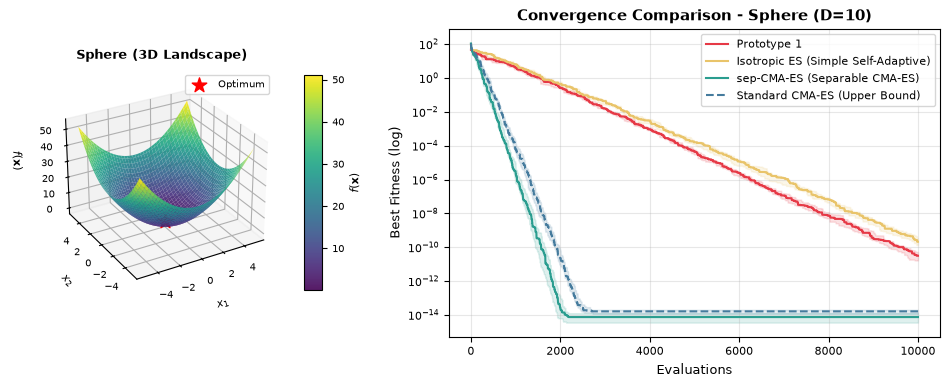

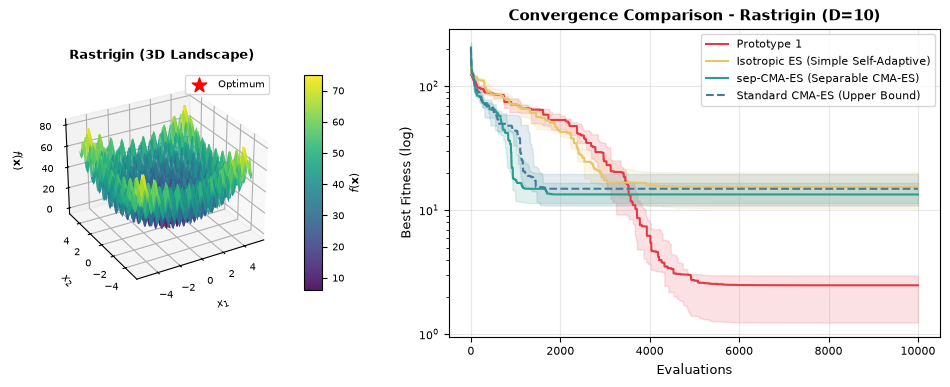

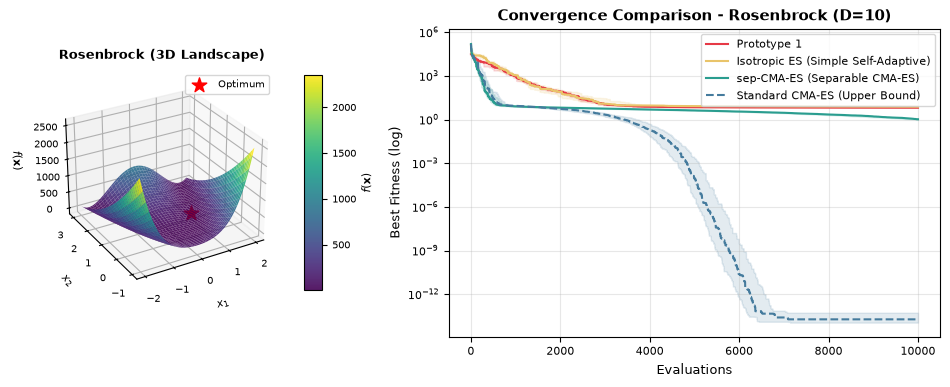

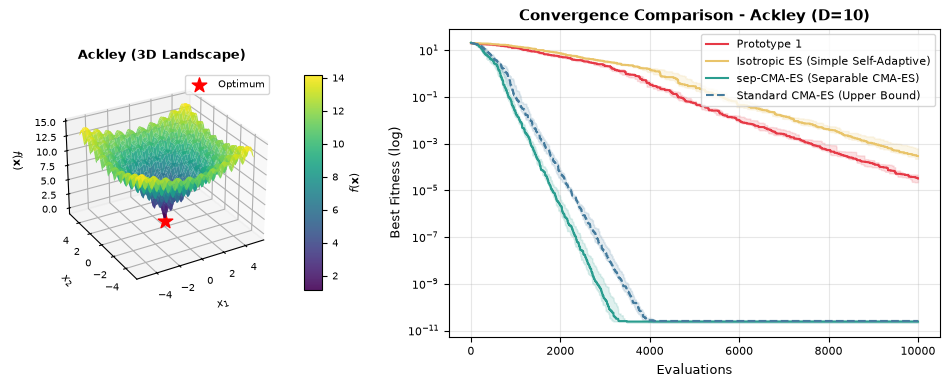

In [7]:
# --- Generate and display 3D landscape and convergence plots ---
for bname, binfo in BENCHMARKS.items():
    if bname in results:
        fig_path = os.path.join(FIGURES_DIR, f"exp1_{bname.lower()}_3d.png")
        plot_benchmark_summary(bname, binfo, results[bname], MAX_EVALS, save_path=fig_path, show=True)


## 5. Statistical Results Summary Table


In [8]:
print("=" * 105)
print(f" EXPERIMENT 1 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations | D={DIM})")
print("=" * 105)
print(f"{'Benchmark Function':<22} | {'Runner / Optimizer':<38} | {'Median Best':<18} | {'Min (Best Run)':<18}")
print("-" * 105)

if "results" in globals() and results:
    for bname, r_dict in results.items():
        for rname, arr in r_dict.items():
            med_val = np.median(arr[:, -1])
            min_val = np.min(arr[:, -1])
            print(f"{bname:<22} | {rname:<38} | {med_val:<18.4e} | {min_val:<18.4e}")
        print("-" * 105)
print("=" * 105)


 EXPERIMENT 1 RESULTS SUMMARY (10 Seeds | 10000 Max Evaluations | D=10)
Benchmark Function     | Runner / Optimizer                     | Median Best        | Min (Best Run)    
---------------------------------------------------------------------------------------------------------
Sphere                 | Prototype 1                            | 3.1706e-11         | 1.0252e-11        
Sphere                 | Isotropic ES (Simple Self-Adaptive)    | 2.1220e-10         | 7.1193e-11        
Sphere                 | sep-CMA-ES (Separable CMA-ES)          | 7.5449e-15         | 1.3641e-15        
Sphere                 | Standard CMA-ES (Upper Bound)          | 1.6433e-14         | 7.4788e-15        
---------------------------------------------------------------------------------------------------------
Rastrigin              | Prototype 1                            | 2.4874e+00         | 1.1896e-07        
Rastrigin              | Isotropic ES (Simple Self-Adaptive)    | 1.5422e+01    

In [ ]:
# --- Statistical Hypothesis Testing (Wilcoxon Signed-Rank + Holm-Bonferroni) ---
# Validates Table 5.1 of the TFG memory
tests_exp1 = compute_wilcoxon_table_exp1(results)
print("=" * 115)
print(f"{'Benchmark':<12} | {'Opponent Baseline':<20} | {'W/T/L':<8} | {'Stat (W)':<9} | {'p-raw':<12} | {'p-adj':<12} | {'Decision'}")
print("=" * 115)
for t in tests_exp1:
    print(f"{t['benchmark']:<12} | {t['opponent']:<20} | {t['wtl']:<8} | {t['statistic']:<9.1f} | {t['p_raw']:<12.4e} | {t['p_adj']:<12.4e} | {t['decision']}")
print("=" * 115)
